# Plot de $p_T(\mu)$ para Wprime, WJets, TTbar y VV

Este notebook lee los archivos ROOT skimmeados y grafica la distribución de `mu_pt` para señal y fondos.

Asume que tus archivos tienen un árbol llamado `Events` y una rama `weight`.

In [1]:
# Instalar si hace falta:
# pip install uproot awkward numpy matplotlib

import uproot
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


## Configuración de rutas

In [2]:
# Cambia esta ruta si tus skims están en otra carpeta
base_path = Path('/Users/anotherdev/workspace/udea/gfif/Analysis/rootfiles/')
# Ajusta nombres si tus outputs quedaron distintos
samples = {
    'Wprime': base_path / 'WprimeSkim.root',
    'WJets':  base_path / 'WJetsSkim.root',
    'TTbar':  base_path / 'TTbarSkim.root',
    'VV':     base_path / 'VVSkim.root',
}

tree_name = 'Events'

for label, path in samples.items():
    print(label, path, 'exists =', path.exists())


Wprime /Users/anotherdev/workspace/udea/gfif/Analysis/rootfiles/WprimeSkim.root exists = True
WJets /Users/anotherdev/workspace/udea/gfif/Analysis/rootfiles/WJetsSkim.root exists = True
TTbar /Users/anotherdev/workspace/udea/gfif/Analysis/rootfiles/TTbarSkim.root exists = True
VV /Users/anotherdev/workspace/udea/gfif/Analysis/rootfiles/VVSkim.root exists = True


## Cargar `mu_pt` y pesos

In [3]:
data = {}

branches = ['mu_pt', 'met_pt', 'delta_phi_mu_met', 'weight']

for label, path in samples.items():
    if not path.exists():
        print(f'WARNING: no existe {path}')
        continue

    with uproot.open(path) as f:
        tree = f[tree_name]
        arrays = tree.arrays(branches, library='np')

    mu_pt  = arrays['mu_pt']
    met_pt = arrays['met_pt']
    dphi   = arrays['delta_phi_mu_met']

    mT = np.sqrt(2 * mu_pt * met_pt * (1 - np.cos(dphi)))

    data[label] = {
        'mu_pt':            mu_pt,
        'met_pt':           met_pt,
        'delta_phi_mu_met': dphi,
        'mT':               mT,
        'weight':           arrays['weight'],
    }

    print(f'{label}: {len(mu_pt)} eventos')


Wprime: 13050 eventos
WJets: 1935 eventos
TTbar: 267 eventos
VV: 45 eventos


## Plot normalizado a eventos esperados

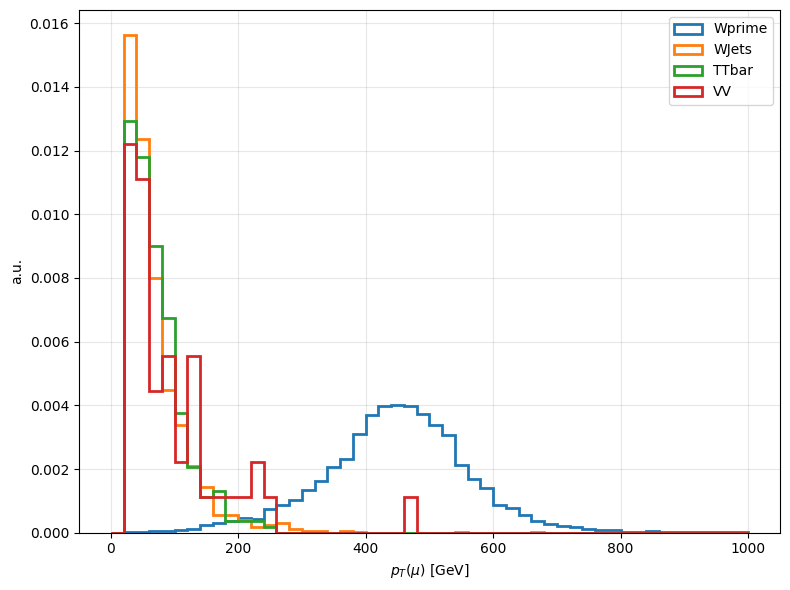

In [4]:
bins = np.linspace(0, 1000, 51)

plt.figure(figsize=(8, 6))

for label, values in data.items():

    w = values["weight"]

    # normalización a área unitaria
    w_norm = w / np.sum(w)

    plt.hist(
        values["mu_pt"],
        bins=bins,
        weights=values["weight"],
        density=True,
        histtype="step",
        linewidth=2,
        label=label,
    )

plt.xlabel(r"$p_T(\mu)$ [GeV]")
plt.ylabel("a.u.")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Plot normalizado a unidad

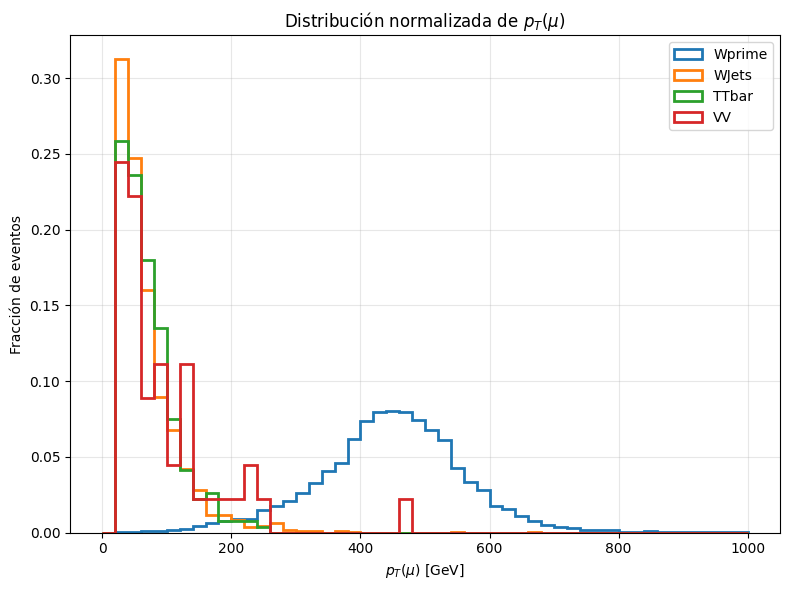

In [5]:
bins = np.linspace(0, 1000, 51)

plt.figure(figsize=(8, 6))

for label, values in data.items():
    weights = np.ones_like(values['mu_pt'], dtype=float) / len(values['mu_pt'])
    plt.hist(
        values['mu_pt'],
        bins=bins,
        weights=weights,
        histtype='step',
        linewidth=2,
        label=label,
    )

plt.xlabel(r'$p_T(\mu)$ [GeV]')
plt.ylabel('Fracción de eventos')
plt.title(r'Distribución normalizada de $p_T(\mu)$')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Guardar figura

## $p_T^{miss}$ (MET)

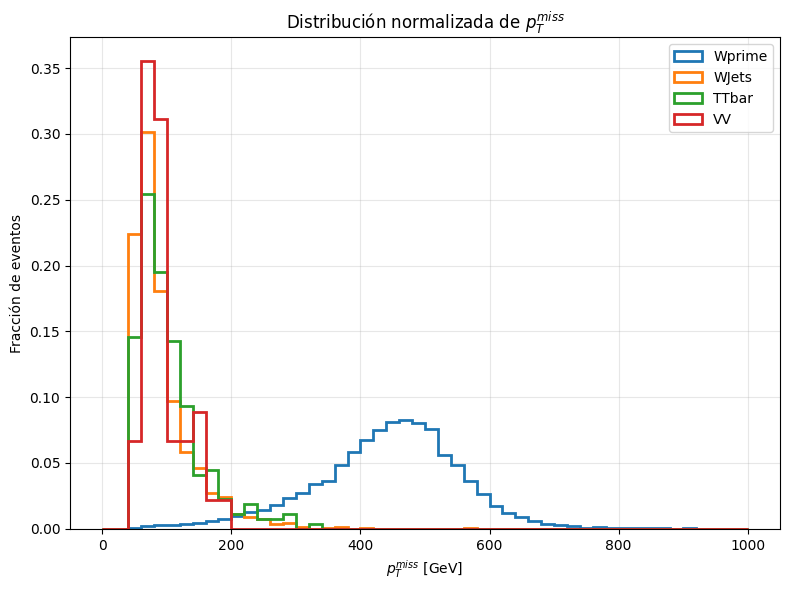

In [6]:
bins_met = np.linspace(0, 1000, 51)

plt.figure(figsize=(8, 6))
for label, values in data.items():
    weights = np.ones_like(values['met_pt'], dtype=float) / len(values['met_pt'])
    plt.hist(
        values['met_pt'],
        bins=bins_met,
        weights=weights,
        histtype='step',
        linewidth=2,
        label=label,
    )

plt.xlabel(r'$p_T^{miss}$ [GeV]')
plt.ylabel('Fracción de eventos')
plt.title(r'Distribución normalizada de $p_T^{miss}$')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## $\Delta\phi(\mu, \text{MET})$

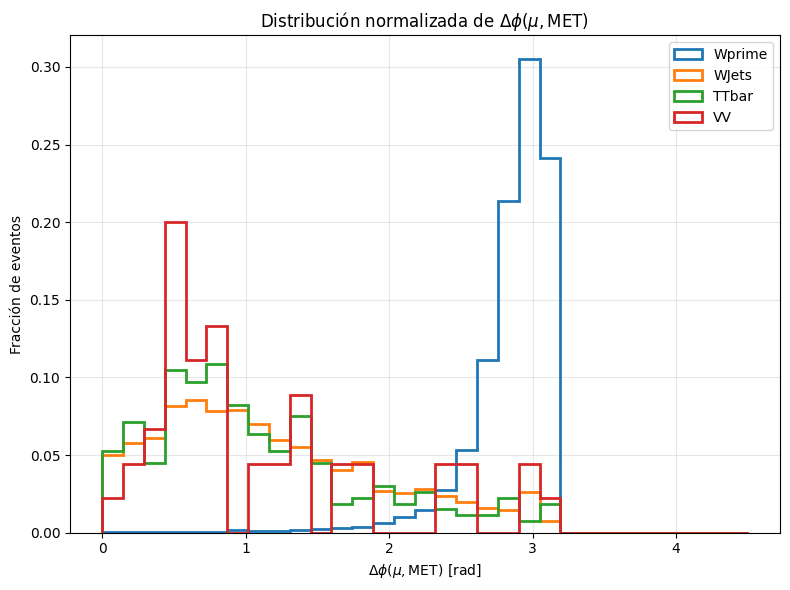

In [7]:
bins_dphi = np.linspace(0, 4.5, 32)

plt.figure(figsize=(8, 6))
for label, values in data.items():
    weights = np.ones_like(values['delta_phi_mu_met'], dtype=float) / len(values['delta_phi_mu_met'])
    plt.hist(
        values['delta_phi_mu_met'],
        bins=bins_dphi,
        weights=weights,
        histtype='step',
        linewidth=2,
        label=label,
    )

plt.xlabel(r'$\Delta\phi(\mu, \mathrm{MET})$ [rad]')
plt.ylabel('Fracción de eventos')
plt.title(r'Distribución normalizada de $\Delta\phi(\mu, \mathrm{MET})$')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Masa transversa $m_T$

$$m_T = \sqrt{2\, p_T^\mu\, p_T^{miss}\,(1 - \cos\Delta\phi(\mu,\mathrm{MET}))}$$

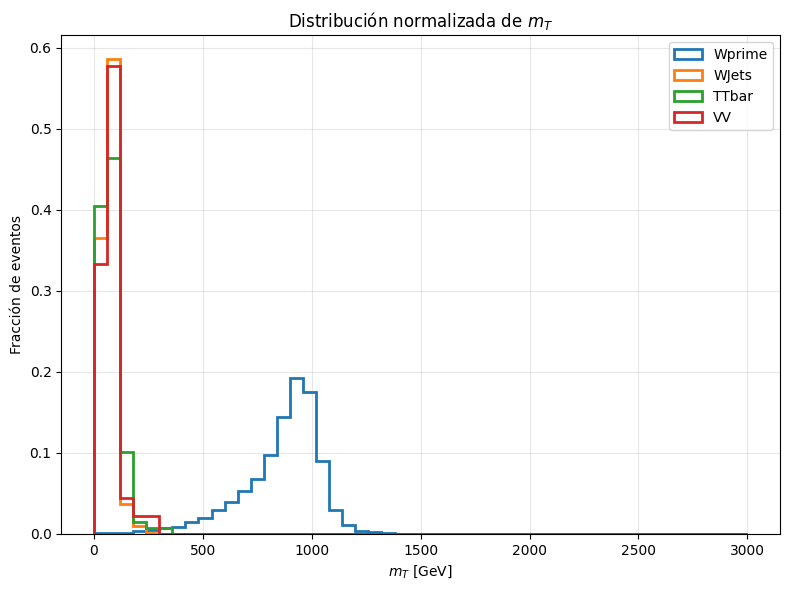

In [8]:
bins_mT = np.linspace(0, 3000, 51)

plt.figure(figsize=(8, 6))
for label, values in data.items():
    weights = np.ones_like(values['mT'], dtype=float) / len(values['mT'])
    plt.hist(
        values['mT'],
        bins=bins_mT,
        weights=weights,
        histtype='step',
        linewidth=2,
        label=label,
    )

plt.xlabel(r'$m_T$ [GeV]')
plt.ylabel('Fracción de eventos')
plt.title(r'Distribución normalizada de $m_T$')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


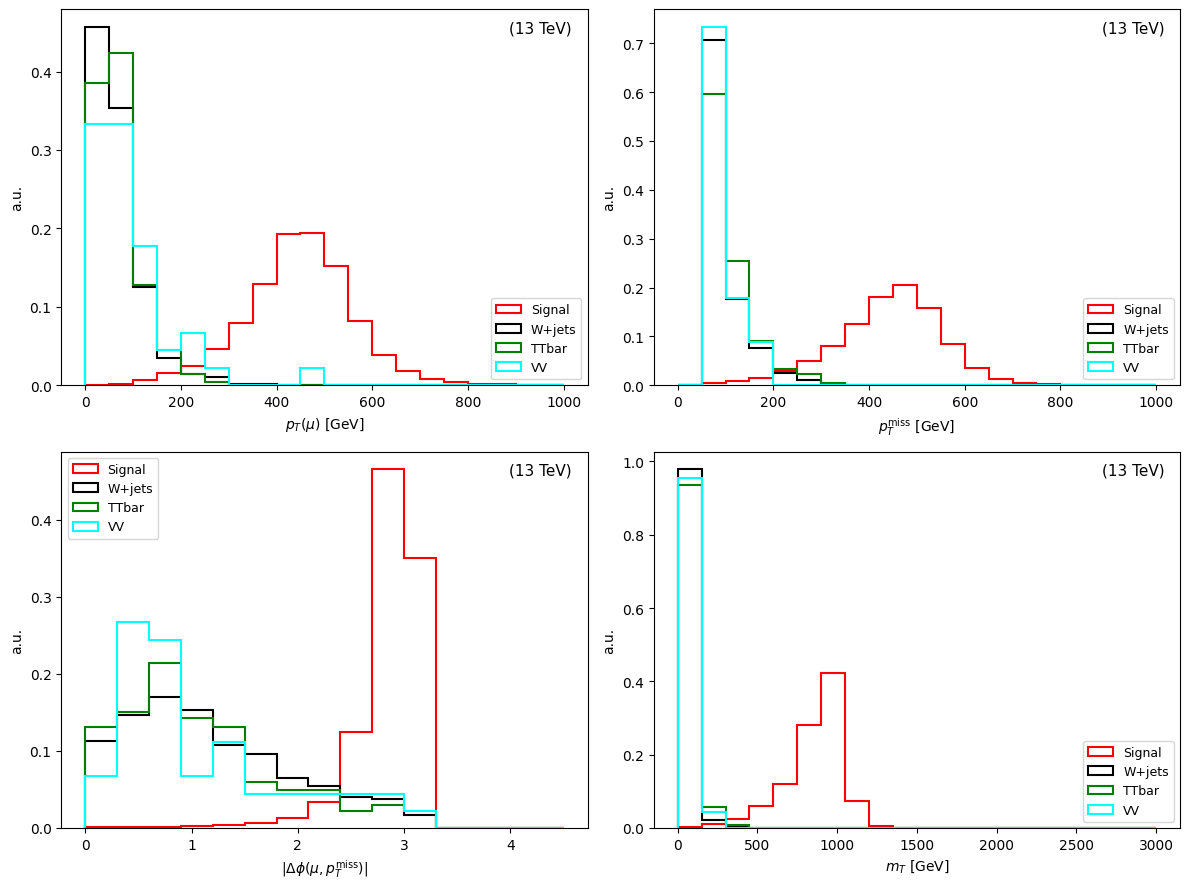

In [9]:

style = {
    'Wprime': {'color': 'red',   'label': 'Signal'},
    'WJets':  {'color': 'black', 'label': 'W+jets'},
    'TTbar':  {'color': 'green', 'label': 'TTbar'},
    'VV':     {'color': 'cyan',  'label': 'VV'},
}

bins_pt   = np.linspace(0, 1000, 21)
bins_met  = np.linspace(0, 1000, 21)
bins_dphi = np.linspace(0, 4.5,  16)
bins_mT   = np.linspace(0, 3000, 21)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

panels = [
    (axes[0, 0], 'mu_pt',            bins_pt,   r'$p_T(\mu)$ [GeV]'),
    (axes[0, 1], 'met_pt',           bins_met,  r'$p_T^\mathrm{miss}$ [GeV]'),
    (axes[1, 0], 'delta_phi_mu_met', bins_dphi, r'$|\Delta\phi(\mu, p_T^\mathrm{miss})|$'),
    (axes[1, 1], 'mT',               bins_mT,   r'$m_T$ [GeV]'),
]

for ax, key, bins, xlabel in panels:
    for name, vals in data.items():
        s = style[name]
        w = np.ones_like(vals[key], dtype=float) / len(vals[key])
        ax.hist(
            vals[key],
            bins=bins,
            weights=w,
            histtype='step',
            linewidth=1.5,
            color=s['color'],
            label=s['label'],
        )
    ax.set_xlabel(xlabel)
    ax.set_ylabel('a.u.')
    ax.text(0.97, 0.97, '(13 TeV)',
            transform=ax.transAxes, ha='right', va='top', fontsize=11)
    ax.legend(fontsize=9)

fig.tight_layout()
plt.show()
